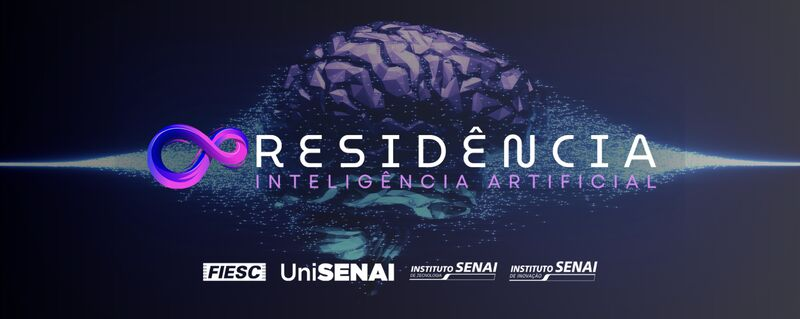

<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>



<h2><b>Unidade Curricular :</b> Visão Computacional</h2>



<h2><b>Professor :</b> Matheus Vanzan</h2>



<h1>Desafio 3 </h1>

---

**Temática**: Modelo para classificação de imagens

**Alunos**: Ana Carolina Dutra Ramos, Camila Gois de Jesus, Guilherme Magalhães Júnior

**Data**: 01/06/2026


---

## Sistema de Recomendação por Similaridade usando CNN Pré-Treinada



### 1. Contexto

Sistemas de recomendação baseados em **similaridade visual** aparecem em grandes plataformas como Amazon, Shopee e Mercado Livre.  
A ideia é simples: dado um produto, encontrar outros produtos **visualmente parecidos**.

Neste desafio, você irá criar um protótipo desse sistema usando **Feature Extraction** com uma CNN pré-treinada.

### 2. Objetivo Geral

Desenvolver um sistema capaz de:

- Carregar um dataset de produtos.
- Extrair **vetores de características** (embeddings) usando Transfer Learning.
- Calcular similaridade entre produtos.
- Recomendar os itens mais parecidos.
- Buscar itens semelhantes a uma **imagem externa** enviada por você.

### 3. Dataset

Use qualquer dataset de produtos, por exemplo:

- *Retail Products Dataset* (Kaggle)  
- *Fashion Product Images*  
- *Shopee Matching* (subset)  
- Ou outro dataset que contenha imagens de produtos

Se preferir, selecione apenas um subconjunto.


### 4. Atividades Obrigatórias

#### **4.1. Preparação dos dados**
- Carregue e organize as imagens.
- Redimensione para o shape necessário (ex.: 224×224).
- Separe treino/validação se necessário.

#### **4.2. Extração de Features com CNN Pré-Treinada**
- Utilize EfficientNetB0 (ou outra da sua escolha).
- Remova a camada final de classificação.
- Gere um vetor de características para cada imagem.

Dica: use `GlobalAveragePooling2D` como saída.

#### **4.3. Construir o Índice de Similaridade**
- Armazene todos os vetores de features em um array NumPy.
- Implemente uma função de distância (cosine ou euclidiana).
- Crie uma função:

```python
def recomendar(img, k=5):
    # retorna as k imagens mais parecidas
````

#### **4.4. Recomendação de Produtos**

* Escolha uma imagem do dataset como consulta.
* Mostre:

  * A imagem de entrada
  * As 5 imagens mais parecidas

#### **4.5. Busca por Imagem Externa**

* Faça upload de uma imagem (de fora do dataset).
* Extraia suas features.
* Busque no dataset as imagens mais similares.
* Mostre o resultado graficamente.

### 5. Entrega

Seu notebook deve conter:

1. Preparação do dataset
2. Construção do extrator de features
3. Extração dos vetores
4. Implementação da função de recomendação
5. Testes com:

   * imagem do dataset
   * imagem externa
6. Visualização das recomendações
7. Pequena análise final:

   * A similaridade fez sentido?
   * O que você melhoraria?

# SOLUÇÃO

In [1]:
import os
import cv2
import random
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from IPython.display import display
from PIL import Image

from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import utils

print(tf.__version__)

2.20.0


In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

In [3]:
pip install kaggle

In [4]:
import os

os.environ['KAGGLE_API_TOKEN'] = 'KGAT_02d9c2b9ad07986c321c9b64ef96939e'

In [5]:
!kaggle datasets download nirmalsankalana/mini-product-image-and-text-dataset

Dataset URL: https://www.kaggle.com/datasets/nirmalsankalana/mini-product-image-and-text-dataset
License(s): MIT
mini-product-image-and-text-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [6]:
!unzip mini-product-image-and-text-dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: data/58128.jpg          
  inflating: data/58129.jpg          
  inflating: data/5813.jpg           
  inflating: data/58131.jpg          
  inflating: data/58132.jpg          
  inflating: data/58133.jpg          
  inflating: data/58135.jpg          
  inflating: data/58136.jpg          
  inflating: data/58137.jpg          
  inflating: data/58138.jpg          
  inflating: data/58139.jpg          
  inflating: data/5814.jpg           
  inflating: data/58140.jpg          
  inflating: data/58141.jpg          
  inflating: data/58143.jpg          
  inflating: data/58144.jpg          
  inflating: data/58145.jpg          
  inflating: data/58146.jpg          
  inflating: data/58147.jpg          
  inflating: data/58148.jpg          
  inflating: data/58149.jpg          
  inflating: data/5815.jpg           
  inflating: data/58150.jpg          
  inflating: data/58151.jpg          
  inflating: data/58152.jpg          

# **1) EDA**

In [7]:
# Conferindo o tamanho do dataset

caminho = "/content/data"

print(f"Quantidade de imagens: {len(os.listdir(caminho))}")

Quantidade de imagens: 44441


In [8]:
# Carregando os endereços das imagens

arquivos = [
    os.path.join(caminho, nome)
    for nome in os.listdir(caminho)
]

ds = tf.data.Dataset.from_tensor_slices(arquivos)

In [9]:
# Carregando as imagens no 'ds'

def carregar_imagem(caminho):
    img = tf.io.read_file(caminho)
    img = tf.image.decode_jpeg(img, channels=3)
    return img


ds = ds.map(carregar_imagem)

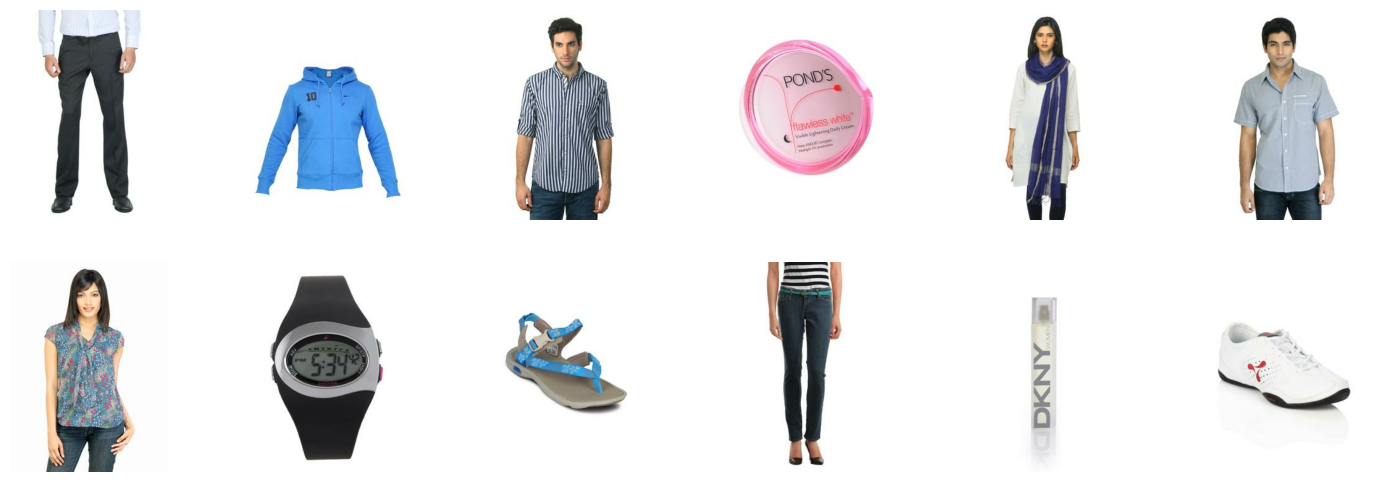

In [10]:
# Verificando algumas imagens do dataset

plt.figure(figsize=(18,6))

for i, img in enumerate(ds.take(12)):

    plt.subplot(2,6,i+1)

    plt.imshow(img.numpy())
    plt.axis("off")

plt.show()

In [11]:
# Verificando as dimensões das imagens do dataset

for img in ds.take(18):
    print(img.shape)

(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)
(341, 256, 3)


# **2) Tratamento dos dados**

In [12]:
# Redimensionando as imagens do dataset

ds = ds.map(
    lambda img: tf.image.resize(img, (256, 256))
)

In [13]:
# Verificando as dimensões das imagens do dataset

for img in ds.take(18):
    print(img.shape)

(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)
(256, 256, 3)


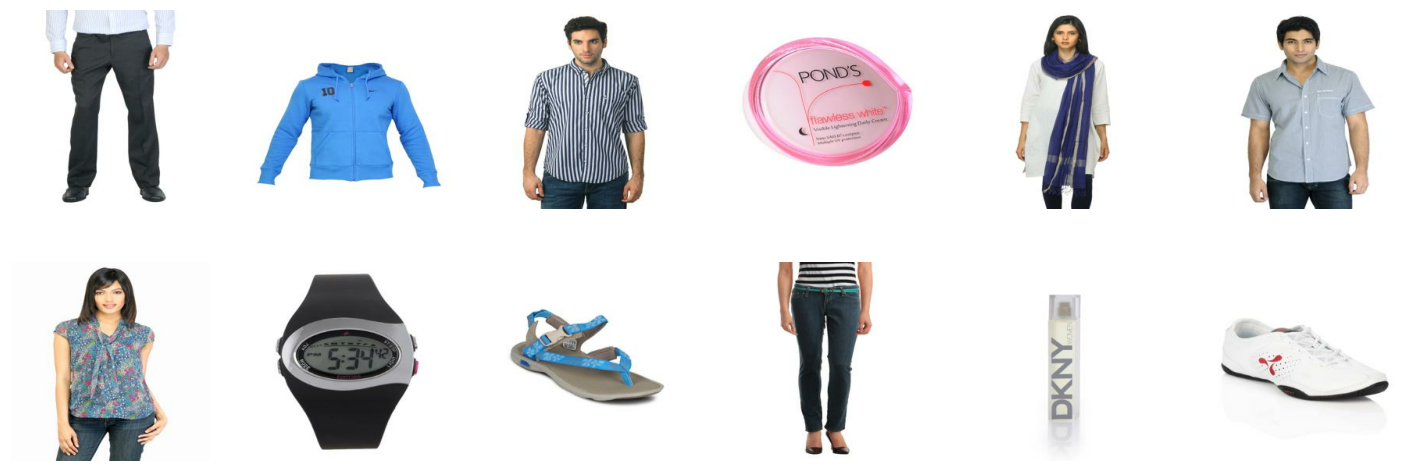

In [14]:
# Verificando algumas imagens do dataset

plt.figure(figsize=(18,6))

for i, img in enumerate(ds.take(12)):

    plt.subplot(2,6,i+1)

    plt.imshow(tf.cast(img, tf.uint8).numpy())
    plt.axis("off")

plt.show()

In [15]:
# Definindo o tamanho do bacth

BATCH_SIZE = 32

ds = ds.batch(BATCH_SIZE)

# **3) Treinando o modelo**

In [16]:
# Ver se o TF enxerga alguma GPU
print(tf.config.list_physical_devices('GPU'))

# Nome do device padrão (vazio se não tiver GPU)
print(tf.test.gpu_device_name())

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
/device:GPU:0


## a) Modelo pré-treinado

In [17]:
from tensorflow.keras.applications.efficientnet import preprocess_input
BaseModel = tf.keras.applications.EfficientNetB0

IMG_SIZE = 256
BATCH_SIZE = 32

In [18]:
base_model = BaseModel(
    include_top=False,
    weights='imagenet',
    pooling='avg',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

## b) Extração de embeddings

In [19]:
embeddings = []
# images_raw = []
# labels_raw = []

for batch_imgs in ds:
    imgs_prepped = preprocess_input(batch_imgs)

    emb = base_model(imgs_prepped)

    embeddings.append(emb.numpy())
    # images_raw.append(batch_imgs.numpy())
    # labels_raw.append(batch_labels.numpy())

embeddings = np.vstack(embeddings)
# images_raw = np.vstack(images_raw)
# labels_raw = np.hstack(labels_raw)

print('Formato dos embeddings:', embeddings.shape)
# print('Formato das imagens:', images_raw.shape)

Formato dos embeddings: (44441, 1280)


## c) Construindo índice de similaridade

In [20]:
print("Formato dos embeddings:", embeddings.shape)

Formato dos embeddings: (44441, 1280)


In [21]:
k = 20

kmeans = KMeans(n_clusters=k, random_state=0)
cluster_ids = kmeans.fit_predict(embeddings)

print("Clusters:", np.unique(cluster_ids))

Clusters: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


In [22]:
# Redução dos embeddings para 2 dimensões com t-SNE

len(embeddings)

44441

In [23]:
n = len(embeddings)

# Configuração do t-SNE
tsne = TSNE(n_components=2, random_state=42)

# Executamos o t-SNE apenas nos embeddings reduzidos
tsne_emb = tsne.fit_transform(embeddings)

/tmp/ipykernel_14186/1403982052.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


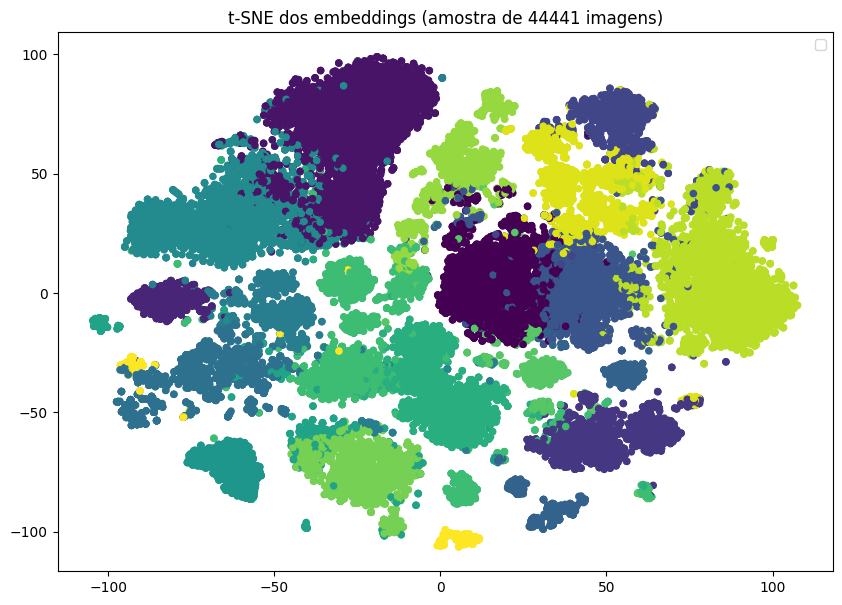

In [24]:
plt.figure(figsize=(10,7))
plt.scatter(tsne_emb[:,0], tsne_emb[:,1], c=cluster_ids, s=20)
plt.title(f"t-SNE dos embeddings (amostra de {n} imagens)")
plt.legend()
plt.show()

## d) Recomendação de produtos

### - Criando a função de k imagens mais parecidas

In [25]:
len(embeddings)

44441

In [26]:
print(embeddings.shape)

(44441, 1280)


In [27]:
# Criando a função de distâncisa usando cosine

from sklearn.metrics.pairwise import cosine_similarity

def similaridade (a, embeddings):
  sim = cosine_similarity(
      a.reshape(1,-1),
      embeddings
  )

  return sim

In [28]:
# Defina a imagem
img = 300

# Defina o K
k = 5

In [29]:
def recomendar(dataset, img, k):

  print("Shape dentro:", embeddings.shape)

  # Definindo a imagem a ser comparada
  imagem = embeddings[img]

  # Executando a função de comparação da imagem escolhida com as demais presentes no embeddings
  similaridades = similaridade (imagem, embeddings)

  # Transformando a matriz 2D resultante em 1 vetor
  similaridades = similaridades.flatten()

  # Colocando os índices em ordem decrescente (maior similaridade)
  indices = np.argsort(similaridades)[::-1]

  # Separando os k índices das k imagens mais similares
  indice_final = []
  for i in range(k):
    indice_final.append(indices[i+1])

  # Imprimindo a imagem escolhida mais as k imagens mais similares

  plt.figure(figsize=(18,3))


  # Imagem original
  plt.subplot(1,6,1)
  plt.imshow(Image.open(dataset[img]))
  plt.title("Consulta")
  plt.axis("off")


  # Imagens similares
  for y, idx in enumerate(indice_final):

      plt.subplot(1,6,y+2)
      plt.imshow(Image.open(dataset[idx]))
      plt.title(f"Top {y+1}")
      plt.axis("off")

  plt.show()

Shape dentro: (44441, 1280)


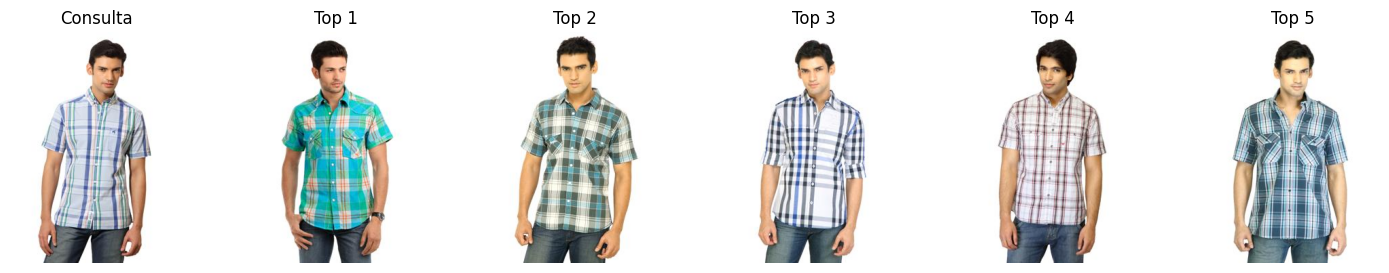

In [30]:
recomendar(arquivos, img, k)

## e) Busca por imagem externa

In [31]:
# Carregando uma nova imagem (externa)


img = tf.io.read_file("/content/Imagem_blusa.jpg")
img = tf.image.decode_jpeg(img, channels=3)
print(img.shape)

(339, 236, 3)


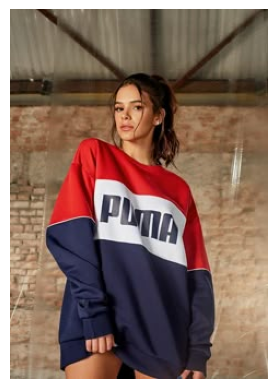

In [32]:
# Visualizando a imagem carregada

plt.imshow(img.numpy())
plt.axis("off")
plt.show()

In [33]:
# Verificando as dimensões dela

img.shape

TensorShape([339, 236, 3])

In [34]:
# Redimensionando a imagen carregada

img = tf.image.resize(img, (256, 256))

In [35]:
img.shape

TensorShape([256, 256, 3])

In [36]:
img_batch = tf.expand_dims(img, axis=0)

In [37]:
img_batch.shape

TensorShape([1, 256, 256, 3])

In [38]:
embedding = []

img_prepped = preprocess_input(img_batch)

emb = base_model(img_prepped)
embedding.append(emb.numpy())
embedding = np.vstack(embedding)

print('Formato do embedding:', embedding.shape)

Formato do embedding: (1, 1280)


In [39]:
len(embeddings)

44441

In [40]:
# Adicionando o embedding da nova imagem ao embedding do dataset carregado inicialmente

embeddings = np.vstack([embeddings, embedding])

In [41]:
len(embeddings)

44442

In [42]:
len(arquivos)

44441

In [43]:
# Adicionando a nova imagem ao dataset

arquivos.append("/content/Imagem_blusa.jpg")

In [44]:
len(arquivos)

44442

Shape dentro: (44442, 1280)


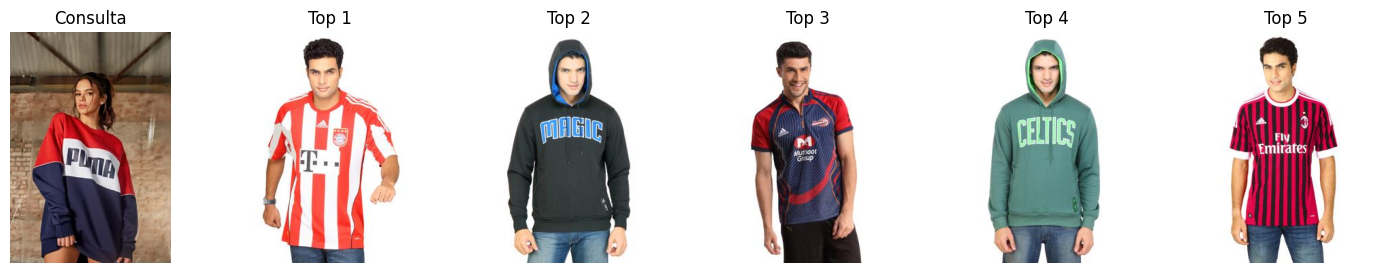

In [45]:
# Aplicando a função de recomendação à nova imagem

recomendar(arquivos, 44441, 5)

## f) Análise final

### **Pergunta: a Similadridade faz sentido? O que você melhoraria?**

#### <font color="green"> **Resposta:** ao aplicar a função de similaridade em uma imagem do dataset original, a mesma retornou outras imagens com grande similaridade. Entretanto quando foi testada essa mesma função com uma imagem externa, ou seja, uma nova imagem não existente no dataset original, a função retornou imagens com alta similaride e também outras com menor similaridade. Aparentemente as informações que fizeram a nossa função apresentar imagens não tão similares, são as cores (vermelho) da imagem escolhida. Sendo assim, o que poderia ser melhorado na prática é trabalhar com o dataset e escala de cinza, para que as cores não sejam tão determinantes para definir similaridade. Outras práticas que poderiam melhorar o resultado, seria o teste de outros modelos como ResNet50, MobileNetV2 e DenseNet121.</font>